In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [2]:
np.random.seed(42)
pd.set_option('display.max_columns', 30)

In [3]:
raw = pd.DataFrame({
    "student_id": range(1, 11),
    "age":   [21, 22, -1, 23, 999, 20, 22, 24, 21, 23],
    "city":  ["Nashik", "Pune", "?", "Mumbai", "NA", "Pune", "Nashik", "", "Mumbai", "Pune"],
    "marks": [78, 82, 65, np.nan, 70, 88, 91, np.nan, 67, 75],})

In [4]:
raw

,student_id,age,city,marks
0,1,21,Nashik,78.0
1,2,22,Pune,82.0
2,3,-1,?,65.0
3,4,23,Mumbai,NaN
4,5,999,NA,70.0
5,6,20,Pune,88.0
6,7,22,Nashik,91.0
7,8,24,,NaN
8,9,21,Mumbai,67.0
9,10,23,Pune,75.0


In [5]:
raw.isnull().sum()

student_id    0
age           0
city          0
marks         2
dtype: int64

In [6]:
raw['age'].describe()

count     10.000000
mean     117.400000
std      309.849139
min       -1.000000
25%       21.000000
50%       22.000000
75%       23.000000
max      999.000000
Name: age, dtype: float64

In [7]:
raw["city"].value_counts()

city
Pune      3
Nashik    2
Mumbai    2
?         1
NA        1
          1
Name: count, dtype: int64

In [8]:
clean = raw.copy()
clean["age"]  = clean["age"].replace([-1, 999], np.nan)
clean["city"] = clean["city"].replace(["?", "NA", ""], np.nan)

In [9]:
clean.isnull().sum()

student_id    0
age           2
city          3
marks         2
dtype: int64

In [10]:
n = 2000
age = np.random.randint(18, 61, size=n)
income = 15000 + 1500 * (age - 18) + np.random.normal(0, 8000, size=n)
income = np.clip(income, 8000, None)

In [11]:
full = pd.DataFrame({"age": age, "income": income})
true_mean = full["income"].mean()
print("TRUE average income (full data):", round(true_mean))
full.head()

TRUE average income (full data): 46814


,age,income
0,56,76758.034733
1,46,63827.324470
2,32,42071.428718
3,60,80249.531392
4,25,26333.608832


In [12]:
mcar = full.copy()
mask = np.random.rand(n) < 0.20
mcar.loc[mask, "income"] = np.nan

In [13]:
mar = full.copy()
prob = np.where(mar["age"] < 30, 0.40, 0.05)
mask = np.random.rand(n) < prob
mar.loc[mask, "income"] = np.nan

In [14]:
mnar = full.copy()
threshold = full["income"].quantile(0.75)
prob = np.where(mnar["income"] > threshold, 0.60, 0.05)
mask = np.random.rand(n) < prob
mnar.loc[mask, "income"] = np.nan

In [15]:
summary = pd.DataFrame({
    "% missing": [0,
                  mcar["income"].isnull().mean() * 100,
                  mar["income"].isnull().mean() * 100,
                  mnar["income"].isnull().mean() * 100],
    "mean of observed income": [true_mean,
                                mcar["income"].mean(),
                                mar["income"].mean(),
                                mnar["income"].mean()],
}, index=["TRUE (full data)", "MCAR", "MAR", "MNAR"]).round(1)

In [16]:
summary

,% missing,mean of observed income
TRUE (full data),0.0,46814.0
MCAR,20.4,47005.6
MAR,15.0,49824.3
MNAR,19.5,42202.2


In [17]:
mar["income_missing"] = mar["income"].isnull()

In [18]:
age_groups = pd.cut(mar["age"], bins=[17, 29, 45, 60], labels=["18-29", "30-45", "46-60"])
mar.groupby(age_groups)["income_missing"].mean().round(3)

age
18-29    0.414
30-45    0.048
46-60    0.049
Name: income_missing, dtype: float64

In [19]:
n = 500
df1 = pd.DataFrame({
    "marks":       np.random.normal(65, 10, n).round(1),
    "attendance":  np.random.normal(80, 8, n).round(1),
    "study_hours": np.random.normal(3, 1, n).round(1),})

In [20]:
df1.loc[np.random.rand(n) < 0.02, "marks"] = np.nan

In [21]:
(df1.isnull().mean() * 100).round(2)

marks          1.4
attendance     0.0
study_hours    0.0
dtype: float64

In [22]:
df1_clean = df1.dropna()

In [23]:
len(df1)

500

In [24]:
len(df1_clean)

493

In [25]:
len(df1) - len(df1_clean)

7

In [26]:
df1b = df1.copy()
for col in df1b.columns:
    df1b.loc[np.random.rand(n) < 0.04, col] = np.nan

In [28]:
(df1b.isnull().mean() * 100).round(1)

marks          4.8
attendance     5.0
study_hours    4.2
dtype: float64

In [29]:
rows_lost = df1b.isnull().any(axis=1).mean() * 100

In [30]:
print("\nBut dropna() would remove", round(rows_lost, 1), "% of ALL rows!")


But dropna() would remove 13.0 % of ALL rows!


In [31]:
n = 1000
df2 = pd.DataFrame({"age": np.random.randint(21, 60, n)})

In [32]:
has_previous_loan = np.random.rand(n) < 0.35
df2["previous_loan_amount"] = np.where(has_previous_loan,
                                    np.random.normal(200000, 50000, n).round(0), np.nan)

In [33]:
default_prob = np.where(has_previous_loan, 0.08, 0.25)
df2["default"] = (np.random.rand(n) < default_prob).astype(int)

In [35]:
round(df2["previous_loan_amount"].isnull().mean() * 100, 1)

65.8

In [36]:
df2.head()

,age,previous_loan_amount,default
0,36,NaN,0
1,38,NaN,0
2,33,214729.0,0
3,57,167658.0,0
4,47,NaN,1


In [37]:
df2["prev_loan_missing"] = df2["previous_loan_amount"].isnull().astype(int)

In [38]:
df2.groupby("prev_loan_missing")["default"].mean().round(3)

prev_loan_missing
0    0.070
1    0.243
Name: default, dtype: float64

In [39]:
df2["previous_loan_amount"] = df2["previous_loan_amount"].fillna(0)
df2[["previous_loan_amount", "prev_loan_missing", "default"]].head()

,previous_loan_amount,prev_loan_missing,default
0,0.0,1,0
1,0.0,1,0
2,214729.0,0,0
3,167658.0,0,0
4,0.0,1,1


In [40]:
n = 1000
marks_true = np.random.normal(65, 10, n)
df3 = pd.DataFrame({"marks": marks_true.copy()})
df3.loc[np.random.rand(n) < 0.08, "marks"] = np.nan

In [41]:
df3["marks"].isnull().sum()

81

In [42]:
round(df3["marks"].skew(), 3), "(close to 0 means symmetric)"

(-0.142, '(close to 0 means symmetric)')

In [43]:
mean_value = df3["marks"].mean()

In [44]:
df3["marks_filled"] = df3["marks"].fillna(mean_value)

In [45]:
round(mean_value, 2)

65.17

In [46]:
df3["marks_filled"].isnull().sum()

0

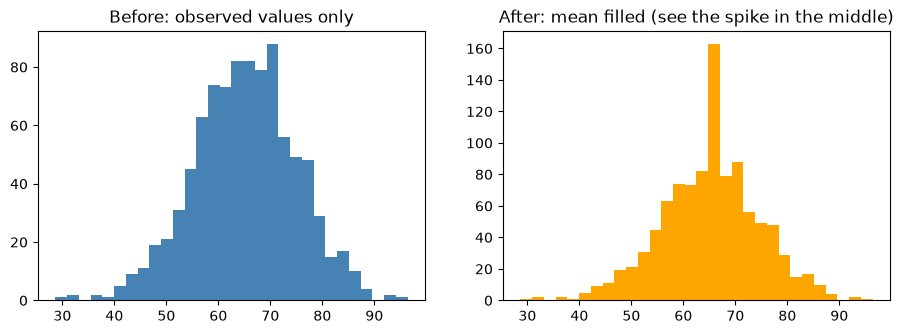

In [47]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(df3["marks"].dropna(), bins=30, color="steelblue")
ax[0].set_title("Before: observed values only")
ax[1].hist(df3["marks_filled"], bins=30, color="orange")
ax[1].set_title("After: mean filled (see the spike in the middle)")
plt.show()

In [48]:
n = 1000
income_true = np.random.lognormal(mean=10.5, sigma=0.8, size=n).round(0)
income_true[:5] = 5_000_000

In [49]:
df4 = pd.DataFrame({"income": income_true.copy()})
df4.loc[np.random.rand(n) < 0.10, "income"] = np.nan

In [50]:
round(df4["income"].mean())

77555

In [51]:
round(df4["income"].median())

37509

In [52]:
round(df4["income"].skew(), 2), "(far from 0 means skewed)"

(13.08, '(far from 0 means skewed)')

In [53]:
df4["filled_mean"]   = df4["income"].fillna(df4["income"].mean())

In [54]:
df4["filled_median"] = df4["income"].fillna(df4["income"].median())

In [55]:
compare = pd.DataFrame({
    "median of column": [np.median(income_true), df4["filled_mean"].median(), df4["filled_median"].median()],
    "mean of column":   [income_true.mean(),     df4["filled_mean"].mean(),   df4["filled_median"].mean()],
}, index=["TRUE (before deleting)", "Filled with MEAN", "Filled with MEDIAN"]).round(0)

In [56]:
compare

,median of column,mean of column
TRUE (before deleting),37314.0,74975.0
Filled with MEAN,41200.0,77555.0
Filled with MEDIAN,37509.0,73751.0


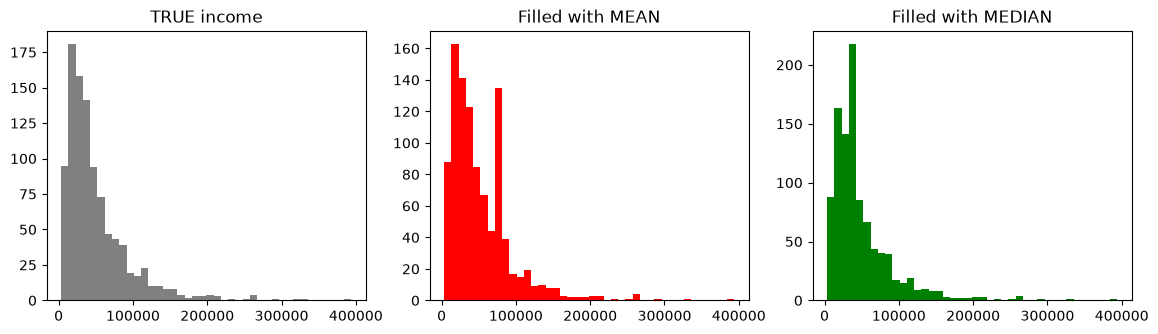

In [57]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5), sharex=True)
limit = 400000                                                  # zoom in, ignore the huge outliers
ax[0].hist(income_true[income_true < limit], bins=40, color="gray");              ax[0].set_title("TRUE income")
ax[1].hist(df4["filled_mean"][df4["filled_mean"] < limit], bins=40, color="red");   ax[1].set_title("Filled with MEAN")
ax[2].hist(df4["filled_median"][df4["filled_median"] < limit], bins=40, color="green"); ax[2].set_title("Filled with MEDIAN")
plt.show()

In [58]:
n = 1000
df5 = pd.DataFrame({
    "payment_method": np.random.choice(["UPI", "Card", "Cash"], size=n, p=[0.5, 0.3, 0.2]),
    "cabin":          np.random.choice(["A", "B", "C"], size=n),})

In [59]:
df5["payment_method"] = df5["payment_method"].astype(object)
df5["cabin"] = df5["cabin"].astype(object)

In [60]:
df5.loc[np.random.rand(n) < 0.10, "payment_method"] = np.nan
df5.loc[np.random.rand(n) < 0.70, "cabin"] = np.nan 

In [62]:
(df5.isnull().mean() * 100).round(1)

payment_method    10.1
cabin             68.6
dtype: float64

In [63]:
mode_value = df5["payment_method"].mode()[0]

In [64]:
mode_value

'UPI'

In [65]:
df5["payment_filled"] = df5["payment_method"].fillna(mode_value)

In [66]:
before = df5["payment_method"].value_counts(normalize=True).round(3)
after  = df5["payment_filled"].value_counts(normalize=True).round(3)
pd.DataFrame({"before (observed)": before, "after (mode filled)": after})

,before (observed),after (mode filled)
UPI,0.495,0.546
Card,0.310,0.279
Cash,0.195,0.175


In [67]:
df5["cabin_filled"] = df5["cabin"].fillna("Unknown")
df5["cabin_filled"].value_counts()

cabin_filled
Unknown    686
C          111
A          102
B          101
Name: count, dtype: int64

In [68]:
dates = pd.date_range("2026-01-01", periods=60, freq="D")
true_temp = 25 + 5 * np.sin(np.arange(60) / 60 * 2 * np.pi * 2) + np.random.normal(0, 0.5, 60)
ts_true = pd.Series(true_temp, index=dates)

In [69]:
ts = ts_true.copy()
missing_positions = [10, 11, 12, 25, 40, 41, 42, 43]
ts.iloc[missing_positions] = np.nan

In [70]:
ts.isnull().sum()

8

In [72]:
filled = pd.DataFrame({
    "mean":        ts.fillna(ts.mean()),
    "ffill":       ts.ffill(),
    "bfill":       ts.bfill(),
    "interpolate": ts.interpolate(method="time"),})

In [73]:
errors = {}
for name in filled.columns:
    errors[name] = (filled[name].iloc[missing_positions] - ts_true.iloc[missing_positions]).abs().mean()

In [74]:
pd.Series(errors, name="Mean absolute error").round(2)

mean           3.79
ffill          1.51
bfill          1.38
interpolate    0.36
Name: Mean absolute error, dtype: float64

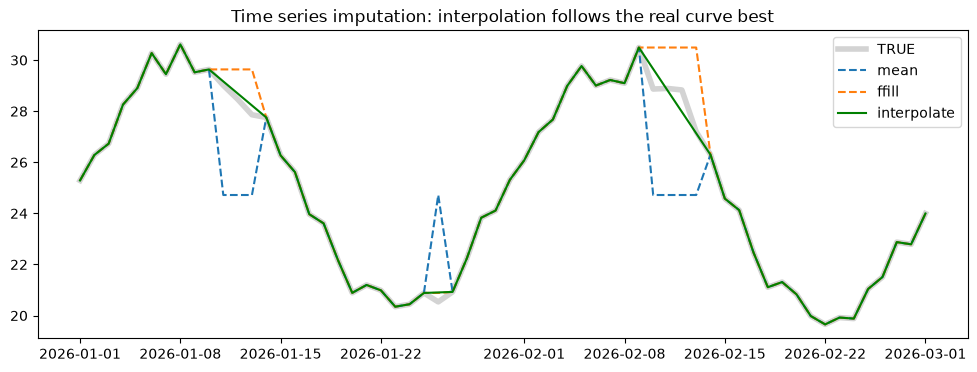

In [75]:
plt.figure(figsize=(12, 4))
plt.plot(ts_true, color="lightgray", linewidth=4, label="TRUE")
plt.plot(filled["mean"],        "--", label="mean")
plt.plot(filled["ffill"],       "--", label="ffill")
plt.plot(filled["interpolate"], "-",  color="green", label="interpolate")
plt.legend()
plt.title("Time series imputation: interpolation follows the real curve best")
plt.show()

In [76]:
n = 500
height = np.random.normal(165, 10, n)
weight = 0.9 * (height - 100) + np.random.normal(0, 4, n)
age = np.random.randint(18, 70, n)

In [77]:
df7_true = pd.DataFrame({"height": height, "weight": weight, "age": age})

In [78]:
df7 = df7_true.copy()
prob = np.where(df7["age"] > 40, 0.25, 0.05)
miss_mask = np.random.rand(n) < prob
df7.loc[miss_mask, "weight"] = np.nan

In [79]:
df7["weight"].isnull().sum()

72

In [80]:
df7.head()

,height,weight,age
0,166.735797,57.140822,21
1,161.270058,53.246510,54
2,145.165113,43.317172,50
3,169.438902,67.777573,36
4,188.348217,84.702118,43


In [81]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

In [82]:
scaler = StandardScaler()
scaled = scaler.fit_transform(df7)

In [83]:
mean_filled = SimpleImputer(strategy="mean").fit_transform(df7)

In [84]:
knn_scaled = KNNImputer(n_neighbors=5).fit_transform(scaled)
knn_filled = scaler.inverse_transform(knn_scaled)

In [85]:
iter_scaled = IterativeImputer(random_state=0).fit_transform(scaled)
iter_filled = scaler.inverse_transform(iter_scaled)

In [86]:
weight_col = 1
truth = df7_true["weight"].values[miss_mask]

In [87]:
def rmse(filled_array):
    predicted = filled_array[miss_mask, weight_col]
    return np.sqrt(np.mean((predicted - truth) ** 2))

In [88]:
pd.Series({
    "Mean imputer": rmse(mean_filled),
    "KNN imputer": rmse(knn_filled),
    "Iterative imputer": rmse(iter_filled),
}, name="RMSE (lower is better)").round(2)

Mean imputer         10.72
KNN imputer           4.66
Iterative imputer     3.68
Name: RMSE (lower is better), dtype: float64

In [89]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score

In [90]:
n = 3000
X = pd.DataFrame({
    "x1": np.random.normal(0, 1, n),
    "x2": np.random.normal(0, 1, n),
    "x3": np.random.normal(0, 1, n),})

In [91]:
y = ((X["x1"] + 0.5 * X["x2"] + np.random.normal(0, 0.5, n)) > 0).astype(int)

In [92]:
X.loc[np.random.rand(n) < 0.30, "x1"] = np.nan

In [93]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

In [94]:
X_train["x1"].isnull().sum()

621

In [95]:
model_native = HistGradientBoostingClassifier(random_state=0)
model_native.fit(X_train, y_train)
acc_native = accuracy_score(y_test, model_native.predict(X_test))

In [96]:
median_x1 = X_train["x1"].median()
Xtr_filled = X_train.fillna({"x1": median_x1})
Xte_filled = X_test.fillna({"x1": median_x1})

In [97]:
model_filled = HistGradientBoostingClassifier(random_state=0)
model_filled.fit(Xtr_filled, y_train)
acc_filled = accuracy_score(y_test, model_filled.predict(Xte_filled))

In [98]:
round(acc_native, 3)

0.783

In [99]:
round(acc_filled, 3)

0.781

In [100]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

In [101]:
n = 4000
default = (np.random.rand(n) < 0.20).astype(int)
age = np.random.randint(21, 65, n)
income = np.random.normal(60000 - 15000 * default, 15000)

In [102]:
hide_prob = np.where(default == 1, 0.60, 0.10)
income = np.where(np.random.rand(n) < hide_prob, np.nan, income)

In [103]:
df9 = pd.DataFrame({"age": age, "income": income})

In [104]:
round(df9["income"].isnull().mean() * 100, 1)

19.4

In [105]:
round(default[df9["income"].isnull()].mean(), 3)

0.627

In [106]:
round(default[df9["income"].notnull()].mean(), 3)

0.095

In [107]:
X9_train, X9_test, y9_train, y9_test = train_test_split(df9, default, test_size=0.3, random_state=1)

In [108]:
pipe_a = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale",  StandardScaler()),
    ("model",  LogisticRegression()),])

In [109]:
pipe_b = Pipeline([
    ("impute", SimpleImputer(strategy="median", add_indicator=True)),
    ("scale",  StandardScaler()),
    ("model",  LogisticRegression()),])

In [110]:
for name, pipe in [("Median only", pipe_a), ("Median + indicator", pipe_b)]:
    pipe.fit(X9_train, y9_train)
    auc = roc_auc_score(y9_test, pipe.predict_proba(X9_test)[:, 1])
    print(name, "-> AUC:", round(auc, 3))

Median only -> AUC: 0.634
Median + indicator -> AUC: 0.834


In [111]:
n = 1000
marks = pd.Series(np.random.normal(65, 12, n))
marks[np.random.rand(n) < 0.15] = np.nan

In [112]:
train, test = train_test_split(marks, test_size=0.3, random_state=1)

In [113]:
wrong_value = marks.median()
right_value = train.median()

In [116]:
round(wrong_value, 3)

64.408

In [117]:
round(right_value, 3)

64.048

In [118]:
from sklearn.model_selection import cross_val_score

In [119]:
scores = cross_val_score(pipe_b, df9, default, cv=5, scoring="roc_auc")

In [120]:
scores.round(3)

array([0.814, 0.854, 0.86 , 0.852, 0.865])

In [121]:
scores.mean().round(3)

0.849

In [122]:
n = 1000
x = np.random.normal(50, 10, n)
y = 2 * x + np.random.normal(0, 8, n)

In [123]:
d = pd.DataFrame({"x": x, "y": y})
d_missing = d.copy()
d_missing.loc[np.random.rand(n) < 0.30, "y"] = np.nan
d_filled = d_missing.fillna({"y": d_missing["y"].mean()})

In [124]:
round(d["y"].std(), 2), "| after mean fill:", round(d_filled["y"].std(), 2)

(21.25, '| after mean fill:', 17.53)

In [125]:
round(d["x"].corr(d["y"]), 3), "| after mean fill:", round(d_filled["x"].corr(d_filled["y"]), 3)

(0.924, '| after mean fill:', 0.753)

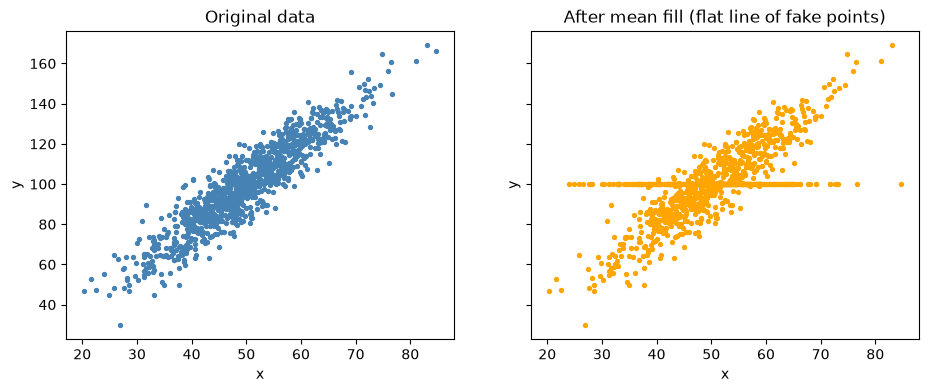

In [126]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
ax[0].scatter(d["x"], d["y"], s=8, color="steelblue");   ax[0].set_title("Original data")
ax[1].scatter(d_filled["x"], d_filled["y"], s=8, color="orange"); ax[1].set_title("After mean fill (flat line of fake points)")
for a in ax:
    a.set_xlabel("x"); a.set_ylabel("y")
plt.show()